# League of Legends: Data Exploration

This starter notebook only loads and previews the original dataset. Run it with the project's Python 3.12 `.venv`. Exploration, feature engineering, and modeling will begin with the team.

In [182]:
from pathlib import Path

import pandas as pd

In [183]:
# Support notebooks launched from the repository root or notebooks/.
data_path = Path("data/raw/lol_ranked_games.csv")
if not data_path.is_file():
    data_path = Path("../data/raw/lol_ranked_games.csv")

df = pd.read_csv(data_path)
print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")

Rows: 242,572 | Columns: 59


In [184]:
df.head()

,gameId,gameDuration,hasWon,frame,goldDiff,expDiff,champLevelDiff,isFirstTower,isFirstBlood,killedFireDrake,...,destroyedBotOuterTurret,lostTopOuterTurret,lostMidOuterTurret,lostBotOuterTurret,kills,deaths,assists,wardsPlaced,wardsDestroyed,wardsLost
0,4546233126,1443000,1,10,-448,-147,-0.2,0,1,0,...,0,0,0,0,4,7,5,21,3,5
1,4546233126,1443000,1,12,-1306,-925,-0.6,0,1,0,...,0,0,0,0,6,11,6,28,4,6
2,4546233126,1443000,1,14,2115,2578,0.4,1,1,0,...,0,0,0,0,10,11,12,35,4,6
3,4546233126,1443000,1,16,1195,2134,0.4,1,1,0,...,0,0,1,0,10,12,12,45,6,10
4,4546233126,1443000,1,18,2931,4382,0.6,1,1,1,...,0,0,1,0,13,13,16,49,7,12


In [185]:
# Inspect column names, data types, and non-missing counts
df.info()

# Count missing values in each column
missing = df.isna().sum()
print("\nTotal missing cells:", missing.sum())
display(missing[missing > 0])

<class 'pandas.DataFrame'>
RangeIndex: 242572 entries, 0 to 242571
Data columns (total 59 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   gameId                   242572 non-null  int64  
 1   gameDuration             242572 non-null  int64  
 2   hasWon                   242572 non-null  int64  
 3   frame                    242572 non-null  int64  
 4   goldDiff                 242572 non-null  int64  
 5   expDiff                  242572 non-null  int64  
 6   champLevelDiff           242572 non-null  float64
 7   isFirstTower             242572 non-null  int64  
 8   isFirstBlood             242572 non-null  int64  
 9   killedFireDrake          242572 non-null  int64  
 10  killedWaterDrake         242572 non-null  int64  
 11  killedAirDrake           242572 non-null  int64  
 12  killedEarthDrake         242572 non-null  int64  
 13  killedElderDrake         242572 non-null  int64  
 14  lostFireDrake  

Series([], dtype: int64)

In [186]:
# Count completely identical rows
print("Duplicate rows:", df.duplicated().sum())

# Check whether a match has multiple records at the same timestamp
print(
    "Duplicate game/timestamp pairs:",
    df.duplicated(subset=["gameId", "frame"]).sum()
)

print("Unique matches:", df["gameId"].nunique())

Duplicate rows: 0
Duplicate game/timestamp pairs: 0
Unique matches: 24912


In [187]:
# Outcomes should only be 0 (loss) or 1 (win)
print("Invalid outcome rows:", (~df["hasWon"].isin([0, 1])).sum())

# Every snapshot of a match should have the same final outcome
outcomes_per_match = df.groupby("gameId")["hasWon"].nunique()
print("Matches with conflicting outcomes:", (outcomes_per_match > 1).sum())

# Count outcomes once per match
match_outcomes = df.drop_duplicates("gameId")["hasWon"]
print("\nMatch outcomes (0 = loss, 1 = win):")
print(match_outcomes.value_counts().sort_index())

Invalid outcome rows: 0
Matches with conflicting outcomes: 0

Match outcomes (0 = loss, 1 = win):
hasWon
0    12373
1    12539
Name: count, dtype: int64


In [188]:
# See which snapshot times exist
print("Frame values:", sorted(df["frame"].unique().tolist()))

# Count available snapshots at our planned prediction times
print("\nSnapshots at selected frames:")
print(df["frame"].value_counts().reindex([10, 14, 18, 20]))

# Inspect the range of recorded match durations
print("\nMatch duration summary:")
print(df["gameDuration"].describe())

Frame values: [10, 12, 14, 16, 18, 20, 22, 24, 26, 28, 30, 32, 34, 36, 38, 40, 42, 44, 46, 48, 50, 52, 54, 56]

Snapshots at selected frames:
frame
10    24912
14    24716
18    23430
20    22632
Name: count, dtype: int64

Match duration summary:
count    2.425720e+05
mean     1.785494e+06
std      3.761901e+05
min      5.490000e+05
25%      1.532000e+06
50%      1.774000e+06
75%      2.025000e+06
max      3.428000e+06
Name: gameDuration, dtype: float64


In [189]:
# Test the interpretation that gameDuration is in milliseconds
timing = df[["gameId", "frame", "gameDuration"]].copy()
timing["duration_minutes"] = timing["gameDuration"] / 60000

# Find snapshots whose frame exceeds the recorded match duration
after_end = timing[timing["frame"] > timing["duration_minutes"]]

print("Rows with frame beyond duration:", len(after_end))
print("Matches affected:", after_end["gameId"].nunique())

display(after_end.head(10))

Rows with frame beyond duration: 10298
Matches affected: 10298


,gameId,frame,gameDuration,duration_minutes
24,4402345420,30,1790000,29.833333
44,4528965743,22,1307000,21.783333
54,4542452868,28,1646000,27.433333
67,4545768539,34,2019000,33.650000
100,4435689189,32,1917000,31.950000
105,4444898629,18,1041000,17.350000
136,4541037936,34,2022000,33.700000
158,4462949679,32,1883000,31.383333
161,4492541971,14,837000,13.950000
178,4544031790,24,1390000,23.166667


In [190]:
# Find the final recorded frame for each match
last_frames = df.groupby("gameId")["frame"].max()

# Check whether flagged rows are final snapshots
is_last = after_end["frame"].eq(after_end["gameId"].map(last_frames))
print("Flagged rows that are NOT final snapshots:", (~is_last).sum())

# Measure the difference between frame and duration
gap_minutes = after_end["frame"] - after_end["duration_minutes"]
print("\nTiming gap in minutes:")
print(gap_minutes.describe())

# Check how many affect our main prediction frame
print("\nFlagged frame-14 rows:", after_end["frame"].eq(14).sum())

Flagged rows that are NOT final snapshots: 0

Timing gap in minutes:
count    10298.000000
mean         0.443337
std          0.248015
min          0.016667
25%          0.250000
50%          0.433333
75%          0.650000
max          1.000000
dtype: float64

Flagged frame-14 rows: 65


In [191]:
# Start with all snapshots labeled frame 14
minute14_all = df.loc[df["frame"].eq(14)].copy()

# Keep matches still in progress at minute 14
# Assumption: gameDuration is recorded in milliseconds
minute14 = minute14_all.loc[
    minute14_all["gameDuration"] > 14 * 60_000
].copy()

print("Original frame-14 rows:", len(minute14_all))
print("Excluded by duration check:", len(minute14_all) - len(minute14))
print("Remaining matches:", len(minute14))
print("Duplicate match IDs:", minute14["gameId"].duplicated().sum())

Original frame-14 rows: 24716
Excluded by duration check: 66
Remaining matches: 24650
Duplicate match IDs: 0


In [192]:
# Select combat and objective counters
count_cols = [
    c for c in minute14.columns
    if c in ["kills", "deaths", "assists"]
    or c.startswith(("killed", "lost", "destroyed"))
]

# Select fields whose names indicate yes/no flags
flag_cols = [c for c in minute14.columns if c.startswith("is")]

print("Count columns checked:", count_cols)
print("\nNegative count values:",
      minute14[count_cols].lt(0).sum().sum())

print("\nFlag columns checked:", flag_cols)
print("Flag values outside 0 or 1:",
      (~minute14[flag_cols].isin([0, 1])).sum().sum())

Count columns checked: ['killedFireDrake', 'killedWaterDrake', 'killedAirDrake', 'killedEarthDrake', 'killedElderDrake', 'lostFireDrake', 'lostWaterDrake', 'lostAirDrake', 'lostEarthDrake', 'lostElderDrake', 'killedBaronNashor', 'lostBaronNashor', 'killedRiftHerald', 'lostRiftHerald', 'destroyedTopInhibitor', 'destroyedMidInhibitor', 'destroyedBotInhibitor', 'lostTopInhibitor', 'lostMidInhibitor', 'lostBotInhibitor', 'destroyedTopNexusTurret', 'destroyedMidNexusTurret', 'destroyedBotNexusTurret', 'lostTopNexusTurret', 'lostMidNexusTurret', 'lostBotNexusTurret', 'destroyedTopBaseTurret', 'destroyedMidBaseTurret', 'destroyedBotBaseTurret', 'lostTopBaseTurret', 'lostMidBaseTurret', 'lostBotBaseTurret', 'destroyedTopInnerTurret', 'destroyedMidInnerTurret', 'destroyedBotInnerTurret', 'lostTopInnerTurret', 'lostMidInnerTurret', 'lostBotInnerTurret', 'destroyedTopOuterTurret', 'destroyedMidOuterTurret', 'destroyedBotOuterTurret', 'lostTopOuterTurret', 'lostMidOuterTurret', 'lostBotOuterTurret

In [193]:
# Identify features not covered by the previous checks
reviewed_cols = count_cols + flag_cols + [
    "gameId", "gameDuration", "frame", "hasWon"
]

remaining_features = [
    c for c in minute14.columns if c not in reviewed_cols
]

print("Remaining features:", remaining_features)

# Inspect their ranges and typical values
display(minute14[remaining_features].describe().T)

Remaining features: ['goldDiff', 'expDiff', 'champLevelDiff', 'wardsPlaced', 'wardsDestroyed', 'wardsLost']


,count,mean,std,min,25%,50%,75%,max
goldDiff,24650.0,75.613022,4198.050104,-20470.0,-2661.75,74.0,2798.00,16786.0
expDiff,24650.0,-57.816146,3167.294927,-17656.0,-2128.00,-50.5,1969.75,14499.0
champLevelDiff,24650.0,-0.008406,0.629919,-4.0,-0.40,0.0,0.40,2.8
wardsPlaced,24650.0,35.702272,35.699987,7.0,21.00,24.0,29.00,404.0
wardsDestroyed,24650.0,4.854239,3.125418,0.0,3.00,4.0,6.00,48.0
wardsLost,24650.0,4.669655,3.117657,0.0,3.00,4.0,6.00,42.0


In [194]:
ward_cols = ["wardsPlaced", "wardsDestroyed", "wardsLost"]

# Check for invalid negative counts
print("Negative ward counts:")
print(minute14[ward_cols].lt(0).sum())

# Inspect the five highest wardsPlaced values
print("\nHighest ward counts at frame 14:")
display(
    minute14.nlargest(5, "wardsPlaced")[["gameId"] + ward_cols]
)

# Inspect earlier snapshots for the match with the highest count
example_id = minute14.loc[minute14["wardsPlaced"].idxmax(), "gameId"]

print("\nEarlier snapshots for the highest-count match:")
display(
    df.loc[
        df["gameId"].eq(example_id) & df["frame"].le(14),
        ["gameId", "frame"] + ward_cols
    ].sort_values("frame")
)

Negative ward counts:
wardsPlaced       0
wardsDestroyed    0
wardsLost         0
dtype: int64

Highest ward counts at frame 14:


,gameId,wardsPlaced,wardsDestroyed,wardsLost
8936,4538941770,404,6,3
101494,4458997158,396,3,3
184511,4522818683,358,4,4
224396,4449855091,349,12,5
57463,4495703296,343,7,2



Earlier snapshots for the highest-count match:


,gameId,frame,wardsPlaced,wardsDestroyed,wardsLost
8934,4538941770,10,318,3,2
8935,4538941770,12,357,5,3
8936,4538941770,14,404,6,3


In [195]:
from sklearn.model_selection import train_test_split

# One outcome per match
matches = df[["gameId", "hasWon"]].drop_duplicates("gameId")

# Reproducible split that approximately preserves win/loss balance
train_ids, test_ids = train_test_split(
    matches["gameId"],
    test_size=0.20,
    random_state=42,
    stratify=matches["hasWon"]
)

# Save each match's assignment in a table
split_ids = matches[["gameId"]].copy()
split_ids["split"] = "train"
split_ids.loc[split_ids["gameId"].isin(test_ids), "split"] = "test"

# Confirm no match appears in both groups
assert set(train_ids).isdisjoint(set(test_ids))

print("All matches:")
print(split_ids["split"].value_counts())

# Check the assignments within our provisional minute-14 dataset
minute14_split = minute14.merge(
    split_ids, on="gameId", validate="one_to_one"
)

print("\nMinute-14 matches:")
print(minute14_split["split"].value_counts())

All matches:
split
train    19929
test      4983
Name: count, dtype: int64

Minute-14 matches:
split
train    19723
test      4927
Name: count, dtype: int64


In [196]:
# Define prediction features
excluded = ["gameId", "gameDuration", "frame", "hasWon", "wardsPlaced"]
feature_cols = [c for c in minute14.columns if c not in excluded]

# Keep identifiers and target alongside the prediction features
baseline_data = minute14[["gameId", "hasWon"] + feature_cols].copy()

# Locate the project's processed-data folder
output_dir = data_path.resolve().parents[2] / "data" / "processed"
output_dir.mkdir(parents=True, exist_ok=True)

baseline_data.to_csv(output_dir / "baseline_data.csv", index=False)
split_ids.to_csv(output_dir / "split_ids.csv", index=False)
pd.DataFrame({"feature": feature_cols}).to_csv(
    output_dir / "feature_columns.csv", index=False
)

print("Saved to:", output_dir)
print("Baseline shape:", baseline_data.shape)
print("Prediction features:", len(feature_cols))

Saved to: C:\Users\bibek\Desktop\CS-363M-ML-Project\data\processed
Baseline shape: (24650, 56)
Prediction features: 54


,matches,percent
hasWon,,
Blue loss,9805,49.71
Blue win,9918,50.29


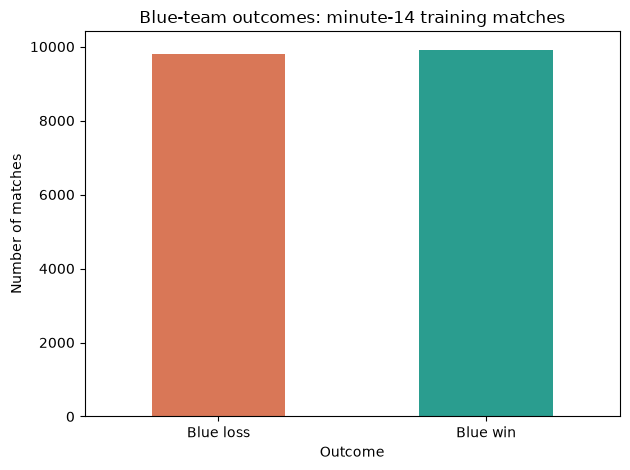

In [197]:
import matplotlib.pyplot as plt

# Use training matches for exploration
train_data = baseline_data.loc[
    baseline_data["gameId"].isin(train_ids)
].copy()

counts = train_data["hasWon"].value_counts().reindex([0, 1], fill_value=0)

display(pd.DataFrame({
    "matches": counts,
    "percent": (counts / counts.sum() * 100).round(2)
}).rename(index={0: "Blue loss", 1: "Blue win"}))

counts.rename(index={0: "Blue loss", 1: "Blue win"}).plot(
    kind="bar", rot=0, color=["#d97757", "#2a9d8f"]
)

plt.title("Blue-team outcomes: minute-14 training matches")
plt.xlabel("Outcome")
plt.ylabel("Number of matches")
plt.tight_layout()
plt.show()

,count,mean,median
hasWon,,,
Blue loss,9805,-2349.882713,-2234.0
Blue win,9918,2485.524098,2310.0


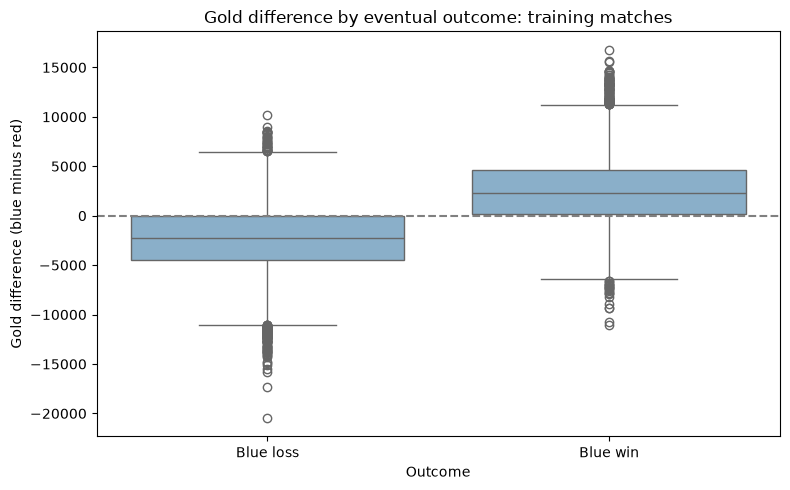

In [198]:
import seaborn as sns

# Compare typical gold differences by outcome
display(
    train_data.groupby("hasWon")["goldDiff"]
    .agg(["count", "mean", "median"])
    .rename(index={0: "Blue loss", 1: "Blue win"})
)

fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=train_data,
    x="hasWon",
    y="goldDiff",
    order=[0, 1],
    color="#80b1d3",
    ax=ax
)

ax.set_xticks([0, 1], ["Blue loss", "Blue win"])
ax.axhline(0, color="gray", linestyle="--")
ax.set_title("Gold difference by eventual outcome: training matches")
ax.set_xlabel("Outcome")
ax.set_ylabel("Gold difference (blue minus red)")
plt.tight_layout()
plt.show()

,matches,wins,win_rate_percent
gold_position,,,
Behind,9732,2308,23.72
Tied,3,2,66.67
Ahead,9988,7608,76.17


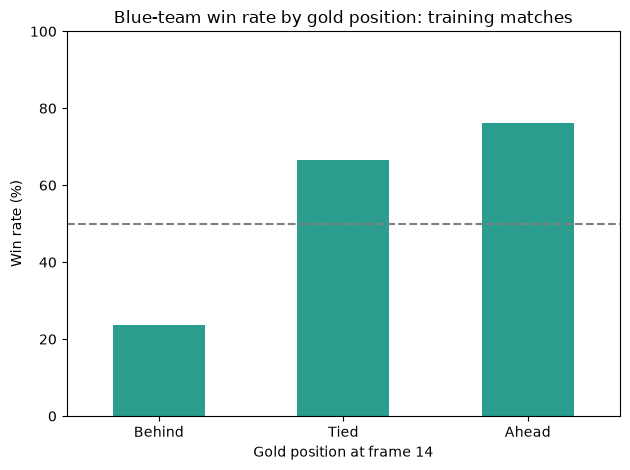

In [199]:
# Classify blue's gold position
gold_position = train_data["goldDiff"].map(
    lambda x: "Behind" if x < 0 else ("Ahead" if x > 0 else "Tied")
).rename("gold_position")

# Calculate match counts and win rates for each position
gold_summary = (
    train_data.groupby(gold_position)["hasWon"]
    .agg(matches="size", wins="sum", win_rate="mean")
    .reindex(["Behind", "Tied", "Ahead"])
)

gold_summary["win_rate_percent"] = gold_summary["win_rate"] * 100

display(gold_summary[["matches", "wins", "win_rate_percent"]].round(2))

gold_summary["win_rate_percent"].plot(
    kind="bar", rot=0, color="#2a9d8f"
)
plt.axhline(50, color="gray", linestyle="--")
plt.title("Blue-team win rate by gold position: training matches")
plt.xlabel("Gold position at frame 14")
plt.ylabel("Win rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

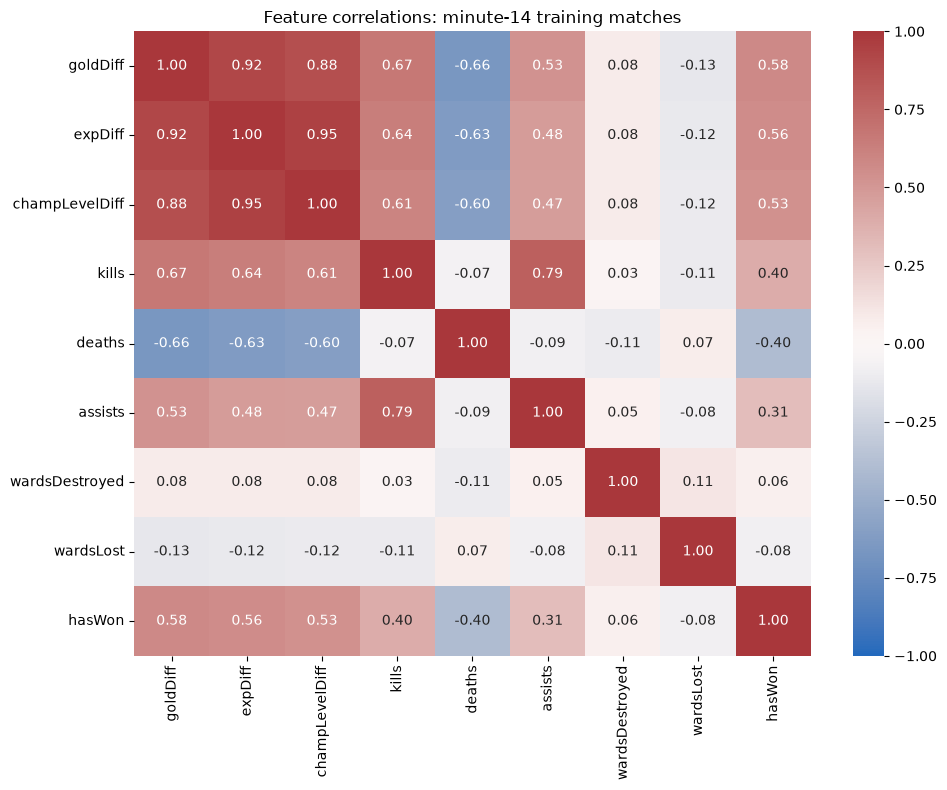

In [200]:
corr_cols = [
    "goldDiff", "expDiff", "champLevelDiff",
    "kills", "deaths", "assists",
    "wardsDestroyed", "wardsLost", "hasWon"
]

correlations = train_data[corr_cols].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap="vlag",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Feature correlations: minute-14 training matches")
plt.tight_layout()
plt.show()

,matches,win_rate,win_rate_percent
dragonDiff,,,
-2,3188,0.24,23.84
-1,4817,0.37,37.22
0,4218,0.50,50.09
1,4475,0.66,65.52
2,3025,0.77,76.69


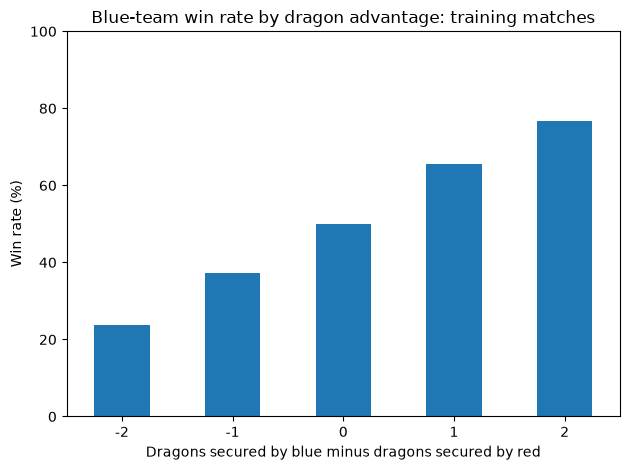

In [201]:
# Create a separate training dataset for engineered features
engineered_train = train_data.copy()

drake_types = ["Fire", "Water", "Air", "Earth", "Elder"]
blue_drakes = [f"killed{d}Drake" for d in drake_types]
red_drakes = [f"lost{d}Drake" for d in drake_types]

engineered_train["dragonDiff"] = (
    engineered_train[blue_drakes].sum(axis=1)
    - engineered_train[red_drakes].sum(axis=1)
)

dragon_summary = (
    engineered_train.groupby("dragonDiff")["hasWon"]
    .agg(matches="size", win_rate="mean")
)
dragon_summary["win_rate_percent"] = dragon_summary["win_rate"] * 100

display(dragon_summary.round(2))

dragon_summary["win_rate_percent"].plot(kind="bar", rot=0)
plt.title("Blue-team win rate by dragon advantage: training matches")
plt.xlabel("Dragons secured by blue minus dragons secured by red")
plt.ylabel("Win rate (%)")
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

In [202]:
# Look up earlier snapshots from the same matches
history10 = df.loc[
    df["frame"].eq(10),
    ["gameId", "goldDiff", "expDiff"]
].set_index("gameId")

# Calculate changes using only earlier information
engineered_train["goldChange10to14"] = (
    engineered_train["goldDiff"]
    - engineered_train["gameId"].map(history10["goldDiff"])
)

engineered_train["expChange10to14"] = (
    engineered_train["expDiff"]
    - engineered_train["gameId"].map(history10["expDiff"])
)

new_features = ["goldChange10to14", "expChange10to14"]

print("Missing engineered values:")
print(engineered_train[new_features].isna().sum())

display(
    engineered_train[
        ["gameId", "goldDiff", "expDiff"] + new_features
    ].head()
)

Missing engineered values:
goldChange10to14    0
expChange10to14     0
dtype: int64


,gameId,goldDiff,expDiff,goldChange10to14,expChange10to14
2,4546233126,2115,2578,2563,2725
10,4438212663,1949,3018,1051,2084
16,4402345420,-1100,384,-945,497
27,4546761795,3451,1529,1144,1433
47,4542452868,1596,630,210,578


In [203]:
# Blue kills minus blue deaths
engineered_train["killDeathDiff"] = (
    engineered_train["kills"] - engineered_train["deaths"]
)

# Outer turrets destroyed by blue minus outer turrets lost
lanes = ["Top", "Mid", "Bot"]

destroyed_outer = [f"destroyed{lane}OuterTurret" for lane in lanes]
lost_outer = [f"lost{lane}OuterTurret" for lane in lanes]

engineered_train["outerTurretDiff"] = (
    engineered_train[destroyed_outer].sum(axis=1)
    - engineered_train[lost_outer].sum(axis=1)
)

display(
    engineered_train[["killDeathDiff", "outerTurretDiff"]]
    .describe().T
)

,count,mean,std,min,25%,50%,75%,max
killDeathDiff,19723.0,0.127668,5.960908,-24.0,-4.0,0.0,4.0,25.0
outerTurretDiff,19723.0,0.032095,0.962608,-3.0,0.0,0.0,1.0,3.0


In [204]:
momentum_view = engineered_train[
    ["goldDiff", "goldChange10to14", "hasWon"]
].copy()

momentum_view["gold_position"] = momentum_view["goldDiff"].map(
    lambda x: "Behind" if x < 0 else ("Ahead" if x > 0 else "Tied")
)

momentum_view["gold_trend"] = momentum_view["goldChange10to14"].map(
    lambda x: "Improving" if x > 0
    else ("Worsening" if x < 0 else "Unchanged")
)

momentum_summary = (
    momentum_view.groupby(["gold_position", "gold_trend"])["hasWon"]
    .agg(matches="size", win_rate="mean")
)

momentum_summary["win_rate_percent"] = (
    momentum_summary["win_rate"] * 100
)

display(
    momentum_summary[["matches", "win_rate_percent"]].round(2)
)

matches  win_rate_percent
gold_position gold_trend                           
Ahead         Improving      8440             79.09
              Unchanged         1            100.00
              Worsening      1547             60.25
Behind        Improving      1509             39.83
              Unchanged         2              0.00
              Worsening      8221             20.76
Tied          Improving         2            100.00
              Worsening         1              0.00

In [205]:
def add_minute14_features(data, snapshots):
    result = data.copy()

    drakes = ["Fire", "Water", "Air", "Earth", "Elder"]
    result["dragonDiff"] = (
        result[[f"killed{d}Drake" for d in drakes]].sum(axis=1)
        - result[[f"lost{d}Drake" for d in drakes]].sum(axis=1)
    )

    history = snapshots.loc[
        snapshots["frame"].eq(10),
        ["gameId", "goldDiff", "expDiff"]
    ].set_index("gameId")

    for source, feature in [
        ("goldDiff", "goldChange10to14"),
        ("expDiff", "expChange10to14")
    ]:
        result[feature] = (
            result[source] - result["gameId"].map(history[source])
        )

    result["killDeathDiff"] = result["kills"] - result["deaths"]

    lanes = ["Top", "Mid", "Bot"]
    result["outerTurretDiff"] = (
        result[[f"destroyed{x}OuterTurret" for x in lanes]].sum(axis=1)
        - result[[f"lost{x}OuterTurret" for x in lanes]].sum(axis=1)
    )

    return result


engineered_data = add_minute14_features(baseline_data, df)

new_features = [
    "dragonDiff", "goldChange10to14", "expChange10to14",
    "killDeathDiff", "outerTurretDiff"
]

print("Engineered dataset shape:", engineered_data.shape)
print("\nMissing engineered values:")
print(engineered_data[new_features].isna().sum())

Engineered dataset shape: (24650, 61)

Missing engineered values:
dragonDiff          0
goldChange10to14    0
expChange10to14     0
killDeathDiff       0
outerTurretDiff     0
dtype: int64


In [206]:
engineered_feature_cols = feature_cols + new_features

engineered_data.to_csv(
    output_dir / "engineered_data.csv", index=False
)

pd.DataFrame({"feature": engineered_feature_cols}).to_csv(
    output_dir / "engineered_feature_columns.csv", index=False
)

definitions = {
    "dragonDiff": "Total dragons secured by blue minus those secured by red",
    "goldChange10to14": "Gold difference at frame 14 minus frame 10",
    "expChange10to14": "Experience difference at frame 14 minus frame 10",
    "killDeathDiff": "Blue kills minus blue deaths at frame 14",
    "outerTurretDiff": "Blue outer turrets destroyed minus outer turrets lost"
}

pd.DataFrame(
    definitions.items(), columns=["feature", "definition"]
).to_csv(output_dir / "engineered_feature_definitions.csv", index=False)

print("Saved engineered dataset, feature list, and definitions.")
print("Use the existing split_ids.csv for train/test assignments.")

Saved engineered dataset, feature list, and definitions.
Use the existing split_ids.csv for train/test assignments.


## Team work starts here

Use the meeting agenda to assign exploration tasks. Keep the raw CSV unchanged. Before modeling, confirm field meanings, select the minute-14 snapshots, and split by match.